In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import precision_recall_curve, average_precision_score

PROC=Path("../data/processed")
id_cols=["admission_type_id","discharge_disposition_id","admission_source_id"]

train=pd.read_csv(PROC/"train.csv",keep_default_na=False,dtype={c: str for c in id_cols})
print(train.shape)

(55989, 51)


In [2]:
target="readmit_30"
X_train=train.drop(columns=[target])
y_train=train[target]

num_cols=X_train.select_dtypes(include="number").columns.tolist()
cat_cols=X_train.select_dtypes(exclude="number").columns.tolist()

print(len(num_cols),"numeric,",len(cat_cols),"categorical")
print("Positive rate:",y_train.mean().round(4))

15 numeric, 35 categorical
Positive rate: 0.0898


In [3]:
preprocessor=ColumnTransformer([("num",StandardScaler(),num_cols),
                                ("cat",OneHotEncoder(handle_unknown="infrequent_if_exist",
                                                     min_frequency=0.01,sparse_output=False),cat_cols)])

In [4]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
scoring={"roc_auc":"roc_auc","pr_auc":"average_precision"}

results,pipes=[],{}

def evaluate(name, model):
    pipe=Pipeline([("prep",preprocessor),("model",model)])
    res=cross_validate(pipe,X_train,y_train,cv=cv,scoring=scoring,n_jobs=-1)
    results.append({
        "model": name,
        "roc_auc": res["test_roc_auc"].mean(),
        "roc_auc_std": res["test_roc_auc"].std(),
        "pr_auc": res["test_pr_auc"].mean(),
        "pr_auc_std": res["test_pr_auc"].std(),
    })
    pipes[name]=pipe
    print(f"{name:22s} ROC-AUC {results[-1]['roc_auc']:.3f} "
          f"(±{results[-1]['roc_auc_std']:.3f})   "
          f"PR-AUC {results[-1]['pr_auc']:.3f} (±{results[-1]['pr_auc_std']:.3f})")

evaluate("Baseline (prior)",DummyClassifier(strategy="prior"))

Baseline (prior)       ROC-AUC 0.500 (±0.000)   PR-AUC 0.090 (±0.000)


In [5]:
evaluate("Logistic Regression",LogisticRegression(C=0.1,class_weight="balanced",
                            max_iter=2000))

Logistic Regression    ROC-AUC 0.645 (±0.003)   PR-AUC 0.163 (±0.004)


In [6]:
evaluate("Random Forest",RandomForestClassifier(n_estimators=300,min_samples_leaf=20,
                                class_weight="balanced_subsample",
                                n_jobs=-1,random_state=42))

Random Forest          ROC-AUC 0.654 (±0.008)   PR-AUC 0.171 (±0.008)


In [7]:
evaluate("Gradient Boosting",
         HistGradientBoostingClassifier(learning_rate=0.05,max_iter=300,
                                        max_leaf_nodes=15,min_samples_leaf=50,
                                        l2_regularization=1.0,
                                        class_weight="balanced",
                                        early_stopping=True,
                                        random_state=42))

Gradient Boosting      ROC-AUC 0.653 (±0.008)   PR-AUC 0.168 (±0.006)


In [8]:
summary=pd.DataFrame(results).set_index("model").round(3)
summary

,roc_auc,roc_auc_std,pr_auc,pr_auc_std
model,,,,
Baseline (prior),0.500,0.000,0.090,0.000
Logistic Regression,0.645,0.003,0.163,0.004
Random Forest,0.654,0.008,0.171,0.008
Gradient Boosting,0.653,0.008,0.168,0.006


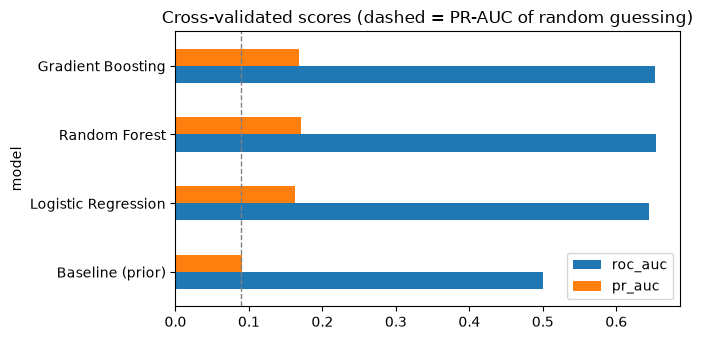

In [9]:
summary[["roc_auc","pr_auc"]].plot(kind="barh",figsize=(7, 3.5))
plt.axvline(y_train.mean(),color="gray",ls="--",lw=1)
plt.title("Cross-validated scores (dashed = PR-AUC of random guessing)")
plt.tight_layout()
plt.show()

Best by PR-AUC: Random Forest


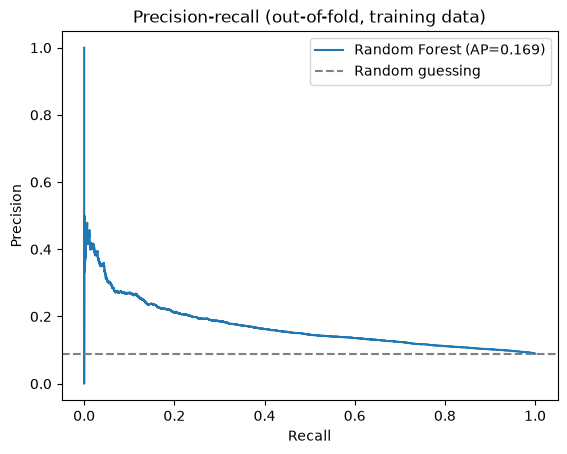

In [10]:
best_name=summary["pr_auc"].idxmax()
best_pipe=pipes[best_name]
print("Best by PR-AUC:",best_name)

oof=cross_val_predict(best_pipe,X_train,y_train,cv=cv,method="predict_proba",n_jobs=-1)[:, 1]

prec,rec,thr=precision_recall_curve(y_train, oof)
plt.plot(rec,prec,label=f"{best_name} (AP={average_precision_score(y_train,oof):.3f})")
plt.axhline(y_train.mean(),color="gray",ls="--",label="Random guessing")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-recall (out-of-fold, training data)")
plt.legend()
plt.show()

In [11]:
for target_recall in [0.4,0.5,0.6,0.7]:
    i=np.where(rec[:-1]>=target_recall)[0].max()
    print(f"Recall ≥ {target_recall:.0%}: threshold {thr[i]:.3f}, "
          f"precision {prec[i]:.3f}, "
          f"flags {(oof >= thr[i]).mean():.0%} of patients")

Recall ≥ 40%: threshold 0.468, precision 0.163, flags 22% of patients
Recall ≥ 50%: threshold 0.437, precision 0.146, flags 31% of patients
Recall ≥ 60%: threshold 0.408, precision 0.136, flags 40% of patients
Recall ≥ 70%: threshold 0.375, precision 0.124, flags 51% of patients


In [12]:
import joblib
Path("../models").mkdir(exist_ok=True)

best_pipe.fit(X_train, y_train)          
joblib.dump(best_pipe,"../models/best_pipeline.joblib")
summary.to_csv("../reports/cv_results.csv")

## Modeling Summary

- Used 5-fold stratified cross-validation on training data.
- Applied preprocessing within a pipeline: scaling numerical features and one-hot encoding categorical features.
- Grouped rare categories (below 1%) using the encoder.
- Handled class imbalance using class weights; no resampling was applied.
- Evaluated four models: Dummy Classifier, Logistic Regression, Random Forest, and Gradient Boosting.
- Metrics: ROC-AUC and PR-AUC (random PR-AUC baseline ≈ 0.09).
- Best model: Random Forest (ROC-AUC: 0.654, PR-AUC: 0.171).
- Differences between the three trained models were small.
- Explored probability thresholds using out-of-fold predictions for recall targets of 40%, 50%, 60%, and 70%.
- Retrained the selected pipeline on the complete training data and saved it as `models/best_pipeline.joblib`.
- Kept the test set untouched for final evaluation.